# Jordan Lake Spatiotemporal Simulation
ASV wind characterization simulation at the Jordan Lake mission domain.

Features:
- STGPKF Formulation
    - Generate Synthetic Data
    - Make estimates based upon existing measurements
- Ergodic Control
- Real-Time SOC-Based speed control
- Hyperparameter Estimation

In [1]:
# Import Packages
using Logging: global_logger
using TerminalLoggers: TerminalLogger
global_logger(TerminalLogger())

using ProgressLogging

using LinearAlgebra
using Random
using Statistics
using Plots
using LaTeXStrings
using Revise
using StaticArrays
using Interpolations
using LazySets
using SpatiotemporalGPs
using JLD2

In [2]:
# Import modules
include("../../../src/jordan_lake_domain.jl")
# include("../../../src/stgpkf.jl")
include("../../../src/kf.jl")
include("../../../src/ngpkf.jl")
include("../../../src/SyntheticData.jl")
include("../../../src/ergodic.jl")
include("../../../src/variograms.jl")
include("../../../src/SOC_Controller.jl")
include("../../../src/simulator_spatial.jl")
include("../../../src/simulator_ST.jl")
include("../../../src/Convex_bound_avoidance.jl")

┌ Warning: Replacing docs for Main.Variograms.hp_fit :: Tuple{Any} in module
│ Main.Variograms
└ @ Base.Docs docs/Docs.jl:243


Main.ConvexBoundAvoidance

# Synthetic Data

In [3]:
# Define simulation time-scale/steps
Δt = 2.5 # seconds
dt_min = Δt/(60) # convert ΔT from seconds to minutes
dt_hrs = Δt/(60*60) # convert ΔT from seconds to hours
T_begin = 9.0; # hours
T_end = 12.0; # hours 
ts_hrs = T_begin:dt_hrs:T_end # hours
ts_min = T_begin*60:dt_min:T_end*60

540.0:0.041666666666666664:720.0

In [4]:
# setup the spatial and temporal kernels
σt = 2.0   # m/s
σs = 1.0   # m/s
lt = 0.25*60.0  # minutes
ls = 0.75   # km

kt = Matern(1/2, σt, lt)
ks = Matern(1/2, σs, ls)

# determine the spatial step size
Δx = 0.10 # km

# create the spatial domain
xs = 0:Δx:1.4
ys = 0:Δx:6.5

grid_pts = vec([@SVector[x, y] for x in xs, y in ys]);

In [5]:
# generate synthetic data
synthetic_data = STGPKF.generate_spatiotemporal_process(xs, ys, dt_min, (T_end-T_begin)*60, ks, kt);

In [6]:
synthetic_data.ts

0.0:0.041666666666666664:179.95833333333334

[ Info: Saved animation to /tmp/jl_VQls7WTC3G.gif


Plots.AnimatedGif("/tmp/jl_VQls7WTC3G.gif")
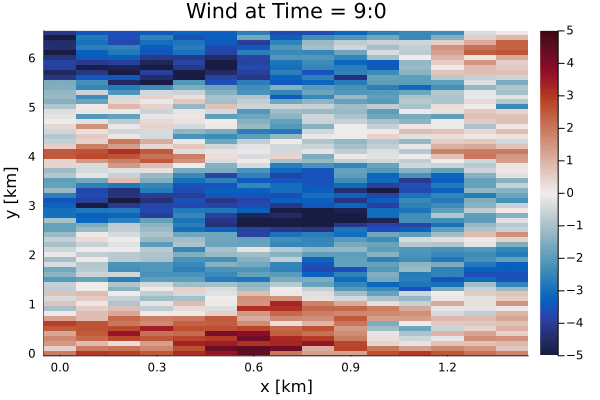

In [7]:
windfield = @animate for time_idx in 1:100:length(synthetic_data.ts)
    heatmap(synthetic_data.xs, synthetic_data.ys, synthetic_data.data[:, :, time_idx]', clims=(-5,5), cmap=:balance, plottype=:wx)
    title!("Wind at Time = $(Int(floor(ts_hrs[time_idx]))):$(Int(floor(mod(ts_hrs[time_idx],1)*60)))")
    xlabel!("x [km]")
    ylabel!("y [km]")
    # plot!(aspect_ratio=:equal)
end
gif(windfield)

[ Info: Saved animation to /tmp/jl_hUXsV8dwl8.gif


Plots.AnimatedGif("/tmp/jl_hUXsV8dwl8.gif")
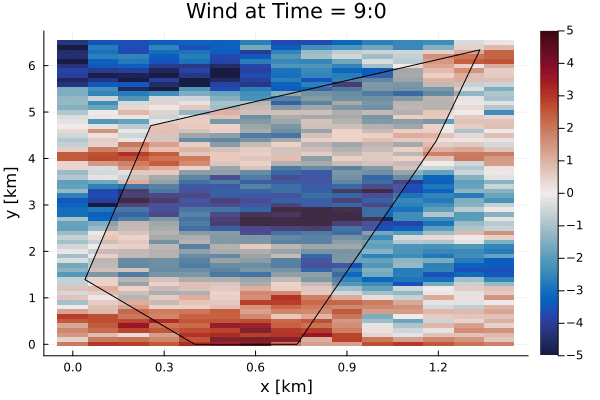

In [8]:
bounded_windfield = @animate for time_idx in 1:100:length(synthetic_data.ts)
    heatmap(synthetic_data.xs, synthetic_data.ys, synthetic_data.data[:, :, time_idx]', clims=(-5,5), cmap=:balance, plottype=:wx)
    polygon_vertices = hcat(JordanLakeDomain.convex_polygon.vertices, JordanLakeDomain.convex_polygon.vertices[:, 1])  # Close the polygon
    plot!(polygon_vertices[1, :], polygon_vertices[2, :], seriestype=:shape, fillalpha=0.2, label="")
    title!("Wind at Time = $(Int(floor(ts_hrs[time_idx]))):$(Int(floor(mod(ts_hrs[time_idx],1)*60)))")
    xlabel!("x [km]")
    ylabel!("y [km]")
    # plot!(aspect_ratio=:equal)
end
gif(bounded_windfield)

## Controller Setup

In [9]:
# Create STGPKF Problem
problem = STGPKFProblem(grid_pts, ks, kt, dt_min)
kern = ks
ngp_grid_x = synthetic_data.xs
ngp_grid_y = synthetic_data.ys
ngpkf_grid = NGPKF.NGPKFGrid(ngp_grid_x, ngp_grid_y, kern)

# ASV Start Location
x0s = [@SVector[0.55, 2.75] for i=1:1]

1-element Vector{SVector{2, Float64}}:
 [0.75, 3.0]

In [10]:
target_q = 0.95

# Set the rated value matrix    
Nx, Ny = length(synthetic_data.xs), length(synthetic_data.ys)
target_q_mat = ones(Nx, Ny)
target_q_mat *= 0.0

# x_domain = range(0, 1.4, length=Nx)
# y_domain = range(0, 6.5, length=Ny)

x_domain = synthetic_data.xs
y_domain = synthetic_data.ys

for i in 1:length(x_domain)
    for j in 1:length(y_domain)
        p = [x_domain[i], y_domain[j]]
        if p ∈ JordanLakeDomain.convex_polygon.polygon
            target_q_mat[i, j] = 0.95
        end
    end
end

In [11]:
function Cfun(p, x)
    return kern(x, p)^2 / kern(p, p)
end
function Rfun(p, x)
    return (kern(x,x) - kern(x, p)^2 / kern(p, p) + 0.5^2)/(Δt)
end


S(p, x)  = Cfun(p, x)^2 / Rfun(p, x)
DxS(p, x) = ForwardDiff.gradient(xx-> S(p, xx), x)

DxS (generic function with 1 method)

In [12]:
using DifferentialEquations
using ForwardDiff

function clarity_prediction(t, q0, C, R, Q)

    k = C / sqrt(Q * R)
    
    q∞ = k / (1 + k)

    γ1 = q∞ - q0
    γ2 = γ1 * (k-1)
    γ3 = (k-1) * q0 - k

    return q∞ * ( 1 + 2 * γ1 / (γ2 + γ3 * exp(2 * k * Q * t)))
end

    
function clarity_time(q0, qf, C, R, Q; tmax=10.0)
    
    println("q0: $(q0)")
    println("qf: $(qf)")
    println("C: $(C)")
    println("R: $(R)")
    println("Q: $(Q)")
    
    if q0 >= qf
        return 0.0
    end

    k = C / sqrt(Q * R)
    println("k: $(k)")
    
    q∞ = k / (1 + k)
    println("q∞: $(q∞)")
    γ1 = q∞ - q0
    γ2 = γ1 * (k-1)
    γ3 = (k-1) * q0 - k

    
        
    if qf >= q∞
        return tmax
    end

    t = log((2*q∞*γ1 - qf*γ2 + q∞*γ2)/((qf - q∞)*γ3))/(2*k*Q)
    println("t: $(t)")

    return min(t, tmax)
end


C_ = Cfun(0,0)
R_ = Rfun(0,0)

k = (C_^2 / R_)
# q(t) = ((-k * t * q_0) + (k * t * q_0)) / ((-k * t * q_0) + (k * t) + 1)

function Clarity_delta_t(current_clarity, target_clarity)
    delta_t = (target_clarity - current_clarity) / ((target_clarity - 1) * k * (current_clarity - 1))
    return delta_t
end

function Clarity_delta_new(current_clarity, target_clarity)
    den = -target_clarity*k + k*current_clarity*target_clarity + k - k*current_clarity
    return delta_t = (target_clarity - current_clarity) / den
end


Clarity_delta_new (generic function with 1 method)

In [13]:
# Controller for weighted 2
using LinearAlgebra, StatsBase

function ergo_controller_weighted_2(t, xs, Mean, w_rated_val, convex_polygon;
        ergo_grid,
        ergo_q_map,
        traj,
        umax= 0.15, #30.0 * 60 / 1000,
        ΔT,
        kwargs...
        )
        
    target_q = 0.95

    # Set the rated value matrix    
    Nx, Ny = length(synthetic_data.xs), length(synthetic_data.ys)
    w_rated = ones(Nx, Ny)
    w_rated *= w_rated_val
  
#   Compute the target matrix 
    lambda_param = 0.05
    delta = -lambda_param*((Mean - w_rated).^2)
    q_target_temp = target_q*(exp.(delta)) 
    
    
    # Mask the matrix such that q_target is zero outisde the domain
    # x_domain = range(0, 1.4, length=Nx)
    # y_domain = range(0, 6.5, length=Ny)
    x_domain = synthetic_data.xs
    y_domain = synthetic_data.ys

    for i in 1:length(x_domain)
        for j in 1:length(y_domain)
            p = [x_domain[i], y_domain[j]]
            if (p ∈ convex_polygon.polygon) == false
                q_target_temp[i, j] = 0.0
            end
        end
    end

    # Get it in the right shape
    q_target_itp = linear_interpolation((x_domain, y_domain), q_target_temp, extrapolation_bc=Interpolations.Line())
    q_target_weighted = q_target_itp(ErgodicController.xs(ergo_grid), ErgodicController.ys(ergo_grid))     

    
    target_spatial_dist = zeros(size(ergo_q_map))
    Qp  = mean(σ_t.^2) # diagm(vec(σ_t .^2 * fuse_measurements_every_ΔT ))      
    
    for i in CartesianIndices(target_spatial_dist)
        if q_target_weighted[i] > ergo_q_map[i]
#             println("here in first cond")
            target_spatial_dist[i] = Clarity_delta_new(ergo_q_map[i], q_target_weighted[i])
        else
            target_spatial_dist[i] = 0.0
        end
    end
        
    u = [ErgodicController.controller_single_integrator_cvx_bound(ergo_grid, x, traj, target_spatial_dist, convex_polygon; umax=umax, do_boundary_correction=true) for x in xs]
    
#     println(u)
    
    return u, q_target_temp

end

ergo_controllers_weighted_2 = [ergo_controller_weighted_2 for i=1:length(x0s)]

1-element Vector{typeof(ergo_controller_weighted_2)}:
 ergo_controller_weighted_2 (generic function with 1 method)

## Generate SOC Target Profile

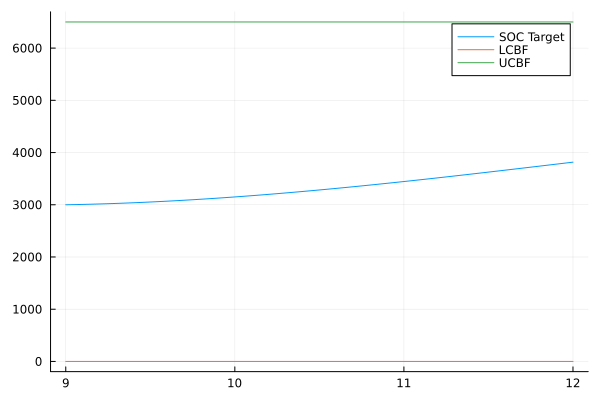

In [14]:
# Generate SOC_Target Profile
soc_begin = 3000
soc_end = 3500
lcbf = SoCController.compute_lcbf(ts_hrs, dt_hrs);
ucbf = SoCController.compute_ucbf(ts_hrs, dt_hrs);
soc_target = SoCController.generate_SOC_target(lcbf, ucbf,  soc_begin, soc_end, ts_hrs, dt_hrs);
plot(ts_hrs, soc_target, label="SOC Target")
plot!(ts_hrs, lcbf, label="LCBF")
plot!(ts_hrs,ucbf, label="UCBF")

## Simulate

In [15]:
fuse_measurements_every_ΔT = 5.0/(60) # hours
recompute_controller_every_ΔT = 5.0 / (120.0*60) # minutes
# σ_t = zeros(15, 66);
σ_t = zeros(66, 15);

w_rated_val = 2.75

@time res_ergo_hp =  SimulatorST.simulate_param_est(ts_min, x0s, soc_begin, ergo_controller_weighted_2, soc_target, w_rated_val, JordanLakeDomain.convex_polygon, problem; 
    ngpkf_grid=ngpkf_grid, 
    EnvData=synthetic_data, 
    σ_meas = 0.5,
    # σ_process= 0.075 * fuse_measurements_every_ΔT,
    Q_process = diagm(vec(σ_t .^2 * fuse_measurements_every_ΔT )) , 
    fuse_measurements_every_ΔT = fuse_measurements_every_ΔT, 
    recompute_controller_every_ΔT = recompute_controller_every_ΔT)

Progress:   0%|                                         |  ETA: N/A


u: [0.25372991812146367, 0.3793708160840595]
u: [0.5618687433827502, 0.39592122615713343]
u: [NaN, NaN]
u: [NaN, NaN]
u: [NaN, NaN]
u: [NaN, NaN]
u: [NaN, NaN]
u: [NaN, NaN]
u: [NaN, NaN]
u: [NaN, NaN]
u: [NaN, NaN]
u: [NaN, NaN]
u: [NaN, NaN]
u: [NaN, NaN]
u: [1.2354525445862934, 1.957774827452325]
u: [1.886901209060966, 1.341204343929363]
u: [1.0605831155603131, 0.5960617095985528]
u: [NaN, NaN]
u: [NaN, NaN]
u: [NaN, NaN]
u: [NaN, NaN]
u: [NaN, NaN]
u: [NaN, NaN]
u: 

Progress:   1%|▎                                        |  ETA: 0:50:30


[NaN, NaN]
u: [NaN, NaN]
u: [NaN, NaN]
u: [0.36361829798263356, -0.07479368204600878]
u: [0.1681436785215652, -0.4935089132642015]
u: [0.007501889546912444, -0.748945765147445]
u: [-0.10406213388745489, -1.0100699571094252]
u: [-0.3208525937415211, -1.349113381612892]
u: [-0.8470606842067179, -1.6569781429670867]
u: [-1.5492297314087693, -1.5508258534345214]
u: [-1.681864936590243, -1.5310855834283816]
u: [-1.6400350734075237, -1.6338635876118621]
u: [NaN, NaN]
u: [NaN, NaN]
u: [NaN, NaN]
u: [NaN, NaN]
u: [NaN, NaN]
u: [NaN, NaN]
u: [NaN, NaN]
u: [NaN, NaN]
u: [NaN, NaN]


Progress:   1%|▍                                        |  ETA: 0:35:57


...

[0.86232003429753, 2.148401597322957]
u: [0.8946149926393715, 2.1351555633900743]
u: [0.8668372251337991, 2.1465829800063783]
u: [-0.9985225986246518, -2.0885827455398074]
u: [-0.9512133377704587, -2.1105493244599405]
u: [-0.8959205400031037, -2.1346080789998143]
u: [-0.9788476948629669, -2.0978757006057775]
u: [-0.9685950860555187, -2.1026290267662127]
u: [-0.8565408114609503, -2.1507122316182947]
u: [-0.6325452661611124, -2.2269063184579405]
u: [-0.49958330895445907, -2.2604516766223606]
u: [-0.3886182537208438, -2.2821483557835784]
u: [-2.0353279894038083, 0.3667037964627513]
u: [-0.8732705331371187, 1.0684117175602905]
u: [-0.4911162522997729, 1.2563805416652465]
u: [0.42904103342588074, 0.56258594221718]
u: [0.3217755465733425, 0.03890025763511695]
u: [0.2412203647425128, -0.26076935942192914]
u: [0.2886370277689589, -0.4211291484415157]
u: [0.25085988450322666, -0.5827820970719763]


Progress: 100%|████████████████████████████████████████▉|  ETA: 0:00:04


u: [0.23035111847064613, -0.6719282002088708]
u: [1.0265877192196686, 2.0566640452710647]
u: [1.2742171858216884, 1.929097742355735]
u: [1.366471597039903, 1.8686842000225574]
u: [NaN, NaN]
u: [NaN, NaN]
u: [NaN, NaN]
u: [NaN, NaN]
1973.105217 seconds (5.56 G allocations: 619.612 GiB, 2.65% gc time, 1.07% compilation time)


Progress: 100%|█████████████████████████████████████████| Time: 0:32:39


Main.SimulatorST.SimResultWeightedSpeedParams{StepRangeLen{Float64, Base.TwicePrecision{Float64}, Base.TwicePrecision{Float64}, Int64}, Vector{Vector{SVector{2, Float64}}}, Vector{Vector{SVector{2, Float64}}}, Vector{Float64}, Vector{Float64}, Vector{Float64}, Vector{Float64}, Vector{Float64}, Vector{Float64}, Vector{Float64}, Vector{Matrix{Float64}}, Vector{Matrix{Float64}}}(540.0:0.041666666666666664:720.0, Vector{SVector{2, Float64}}[[[0.75, 3.0]], [[0.7605720799217277, 3.015807117336836]], [[0.7839832775626756, 3.032303835093383]], [[0.7839832775626756, 3.032303835093383]], [[0.7839832775626756, 3.032303835093383]], [[0.7839832775626756, 3.032303835093383]], [[0.7839832775626756, 3.032303835093383]], [[0.7839832775626756, 3.032303835093383]], [[0.7839832775626756, 3.032303835093383]], [[0.7839832775626756, 3.032303835093383]]  …  [[0.22804628886197767, 1.1572819347586647]], [[0.2384987840496121, 1.1329993473806657]], [[0.24809674731922238, 1.1050023390386294]], [[0.2908712356200419

In [17]:
jldsave("20240909_stgpkf_hp_est_sim.jld2"; res_ergo_hp)

In [18]:
# fuse_measurements_every_ΔT = 5.0/(60*60) # hours
# recompute_controller_every_ΔT = 5.0 / (120.0*60) # minutes
# # σ_t = zeros(15, 66);
# σ_t = zeros(66, 15);

# w_rated_val = 2.75
# f = jldopen("new_stgpkf_known_hp_sim.jld2", "r")

In [19]:
# res_ergo_hp = f["res_ergo_hp"]

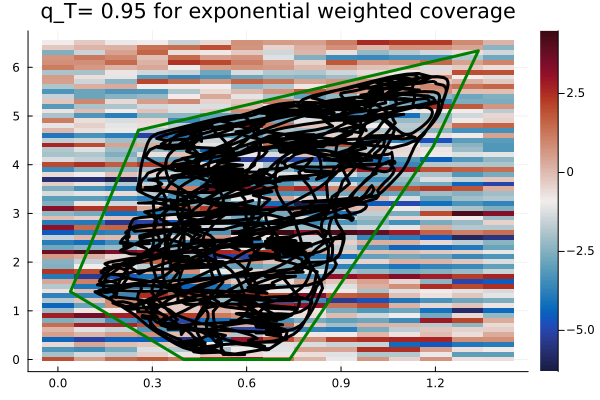

In [20]:
plot()
polygon_vertices = hcat(JordanLakeDomain.convex_polygon.vertices, JordanLakeDomain.convex_polygon.vertices[:, 1])
heatmap(synthetic_data.xs, synthetic_data.ys, synthetic_data.data[:,:,1], cmap = :balance; plottype=:wx)
plot!(polygon_vertices[1, :], polygon_vertices[2, :], seriestype=:shape, fillalpha=0.0, label="", lw = 3, linecolor = "green")
for i=1:length(x0s)
    x = [r[i][1] for r in res_ergo_hp.xs]
    
    y = [r[i][2] for r in res_ergo_hp.xs]
    plot!(x,y, linewidth=3, color=:black, label = "")
end
plot!()

title!("q_T= 0.95 for exponential weighted coverage")

┌ Info: Saved animation to
└ /home/kmgovind/research/adaptive-ocean-exploration-sim/results/fullsim/pathoverrealwind.gif


Plots.AnimatedGif("/home/kmgovind/research/adaptive-ocean-exploration-sim/results/full_sim/path_over_real_wind.gif")
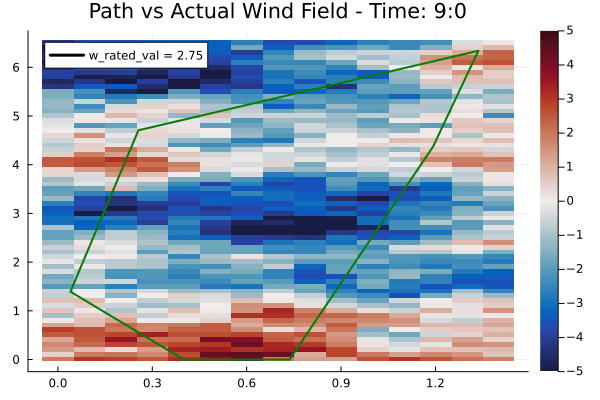

In [25]:
path_over_real_wind = @animate for n = 1:100:length(res_ergo_hp.ts)
    plot()
    heatmap(synthetic_data.xs, synthetic_data.ys, synthetic_data.data[:,:,n]', cmap = :balance; plottype=:wx)
    plot!(polygon_vertices[1, :], polygon_vertices[2, :], seriestype=:shape, fillalpha=0.0, label="", lw = 2, linecolor = "green")
    for i=1:length(x0s)
        x = [r[i][1] for r in res_ergo_hp.xs[1:n]]
        y = [r[i][2] for r in res_ergo_hp.xs[1:n]]
        plot!(x, y, linewidth=3, color=:black, label="w_rated_val = $(w_rated_val)")
    end
    title!("Path vs Actual Wind Field - Time: $(Int(floor(ts_hrs[n]))):$(Int(floor(mod(ts_hrs[n],1)*60)))")
    plot!(clims=(-5.0,5.0))
end
gif(path_over_real_wind, "../results/full_sim/path_over_real_wind.gif")

┌ Warning: No strict ticks found
└ @ PlotUtils /home/kmgovind/.julia/packages/PlotUtils/8mrSm/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils /home/kmgovind/.julia/packages/PlotUtils/8mrSm/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils /home/kmgovind/.julia/packages/PlotUtils/8mrSm/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils /home/kmgovind/.julia/packages/PlotUtils/8mrSm/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils /home/kmgovind/.julia/packages/PlotUtils/8mrSm/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils /home/kmgovind/.julia/packages/PlotUtils/8mrSm/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils /home/kmgovind/.julia/packages/PlotUtils/8mrSm/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils /home/kmgovind/.julia/packages/PlotUtils/8mrSm/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils /home/kmgovind/.julia/packages/PlotUtils/8mrSm/src/ticks.jl:194
┌

Plots.AnimatedGif("/home/kmgovind/research/adaptive-ocean-exploration-sim/results/full_sim/path_over_wind_est.gif")
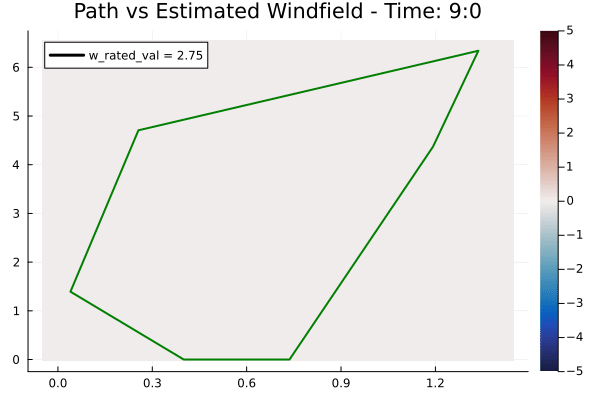

In [26]:
path_over_wind_est = @animate for n = 1:10:length(res_ergo_hp.w_hat_ts)
    plot()
    # ests = reshape(res_ergo_hp.w_hats[n], length(synthetic_data.xs), length(synthetic_data.ys))
    # heatmap(synthetic_data.xs, synthetic_data.ys, ests', cmap = :balance; plottype=:wx)
    heatmap(synthetic_data.xs, synthetic_data.ys, res_ergo_hp.w_hats[n]', cmap=:balance)
    plot!(polygon_vertices[1, :], polygon_vertices[2, :], seriestype=:shape, fillalpha=0.0, label="", lw = 2, linecolor = "green")
    for i=1:length(x0s)
        x = [r[i][1] for r in res_ergo_hp.xs[1:n]]
        y = [r[i][2] for r in res_ergo_hp.xs[1:n]]
        plot!(x, y, linewidth=3, color=:black, label="w_rated_val = $(w_rated_val)")
    end
    title!("Path vs Estimated Windfield - Time: $(Int(floor(res_ergo_hp.w_hat_ts[n]/60))):$(Int(floor(mod(res_ergo_hp.w_hat_ts[n]/60,1)*60)))")
    plot!(clims=(-5.0,5.0))
end
gif(path_over_wind_est, "../results/full_sim/path_over_wind_est.gif")

┌ Warning: No strict ticks found
└ @ PlotUtils /home/kmgovind/.julia/packages/PlotUtils/8mrSm/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils /home/kmgovind/.julia/packages/PlotUtils/8mrSm/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils /home/kmgovind/.julia/packages/PlotUtils/8mrSm/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils /home/kmgovind/.julia/packages/PlotUtils/8mrSm/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils /home/kmgovind/.julia/packages/PlotUtils/8mrSm/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils /home/kmgovind/.julia/packages/PlotUtils/8mrSm/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils /home/kmgovind/.julia/packages/PlotUtils/8mrSm/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils /home/kmgovind/.julia/packages/PlotUtils/8mrSm/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils /home/kmgovind/.julia/packages/PlotUtils/8mrSm/src/ticks.jl:194
┌

Plots.AnimatedGif("/home/kmgovind/research/adaptive-ocean-exploration-sim/results/full_sim/estim_vs_real.gif")
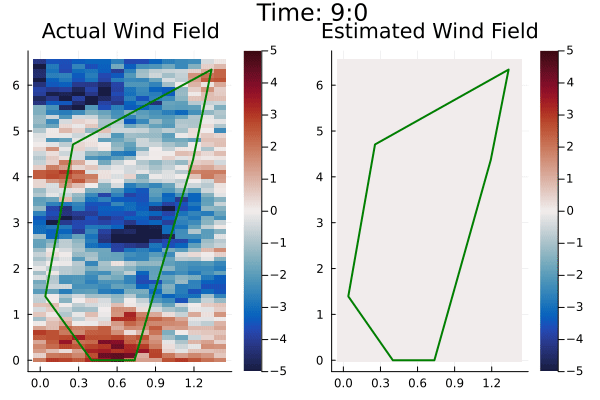

In [27]:
update_idxs = [t in res_ergo_hp.w_hat_ts ? 1 : 0 for t in res_ergo_hp.ts]
w_hat_idx = 1

estim_vs_real = @animate for n = 1:10:length(res_ergo_hp.ts)-1
    plot()
    heatmap1 = heatmap(synthetic_data.xs, synthetic_data.ys, synthetic_data.data[:,:,n]', cmap = :balance; plottype=:wx)
    plot!(polygon_vertices[1, :], polygon_vertices[2, :], seriestype=:shape, fillalpha=0.0, label="", lw = 2, linecolor = "green")
    # for i=1:length(x0s)
    #     x = [r[i][1] for r in res_ergo_hp.xs[1:n]]
    #     y = [r[i][2] for r in res_ergo_hp.xs[1:n]]
    #     plot!(x, y, linewidth=3, color=:black, label="w_rated_val = $(w_rated_val)")
    # end
    plot!(clims=(-5.0,5.0))
    title!("Actual Wind Field")
    heatmap1 = plot!()
    if res_ergo_hp.ts[n] in res_ergo_hp.w_hat_ts
        global w_hat_idx = findfirst(isequal(res_ergo_hp.ts[n]), res_ergo_hp.w_hat_ts)
    end
    heatmap2 = heatmap(synthetic_data.xs, synthetic_data.ys, res_ergo_hp.w_hats[w_hat_idx]', cmap=:balance)
    plot!(polygon_vertices[1, :], polygon_vertices[2, :], seriestype=:shape, fillalpha=0.0, label="", lw = 2, linecolor = "green")
    plot!(clims=(-5.0,5.0))
    title!("Estimated Wind Field")
    heatmap2 = plot!()
    
    p = plot(heatmap1, heatmap2, layout=(1,2), plot_title="Time: $(Int(floor(ts_hrs[n]))):$(Int(floor(mod(ts_hrs[n],1)*60)))")
    # plot!(p, title="Path vs Actual Wind Field - Time: $(Int(floor(ts_hrs[n]))):$(Int(floor(mod(ts_hrs[n],1)*60)))")
    # title!("Path vs Actual Wind Field - Time: $(Int(floor(ts_hrs[n]))):$(Int(floor(mod(ts_hrs[n],1)*60)))")
end
gif(estim_vs_real, "../results/full_sim/estim_vs_real.gif")

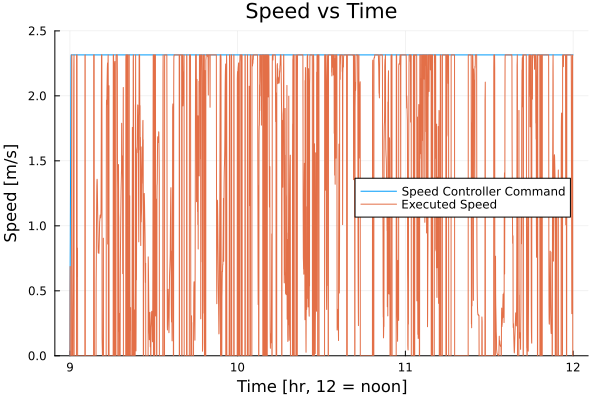

In [28]:
# Collect speeds
u1 = Float64[]
u2 = Float64[]
speed = Float64[]

for i=1:length(res_ergo_hp.us)
    push!(u1, res_ergo_hp.us[i][1][1])
    push!(u2, res_ergo_hp.us[i][1][2])
    push!(speed, norm(res_ergo_hp.us[i][1]))
end

# Speed vs time plot
plot(ts_hrs, res_ergo_hp.speeds, label="Speed Controller Command")
plot!(ts_hrs, speed, label="Executed Speed")
ylims!(0., 2.5)
title!("Speed vs Time")
xlabel!("Time [hr, 12 = noon]")
ylabel!("Speed [m/s]")
plot!(legend=:right)

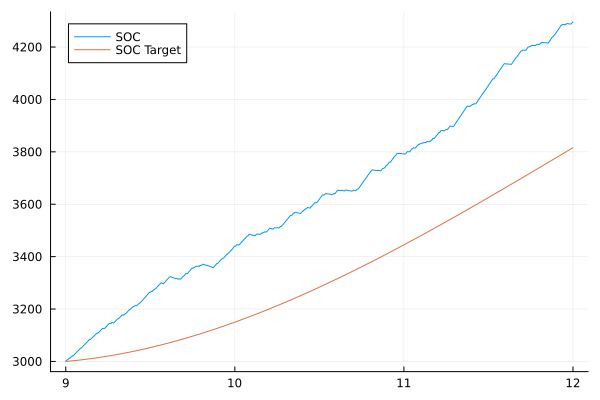

In [29]:
plot(ts_hrs, res_ergo_hp.bs[2:end], label="SOC")
plot!(ts_hrs, soc_target, label="SOC Target")